# K-means clustering

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/unsupervised-learning/02-kmeans-clustering.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

In this notebook, we will use **k-means** to group observations without giving the algorithm any labels. We will start with a small two-feature example, fit a model using scikit-learn, and then see what happens when we change the number of clusters.

K-means assigns each observation to one of $K$ clusters. Each cluster is represented by its **centroid**, the mean of its assigned points. The algorithm aims to make the sum of squared distances from points to their assigned centroids as small as possible:

$$\sum_{i=1}^{n} \lVert \mathbf{x}_i - \boldsymbol{\mu}_{c_i} \rVert^2$$

Here, $c_i$ is the cluster assigned to observation $i$, and $\boldsymbol{\mu}_{c_i}$ is that cluster's centroid.

**Lloyd's algorithm** is a common way to find a k-means solution: it alternates between assigning points to their nearest centroid and updating the centroids. Other algorithms can also be used for k-means. To see Lloyd's algorithm one step at a time, try the [k-means exploration page](kmeans-explorer.qmd).

## 1. Create and inspect the data

We use the same three-blob example as last semester: 300 points with two features. The plotting colors on the right show the groups used to generate the synthetic data; **the model will not receive those labels**. For real unlabeled data, such labels are often unavailable.

Data shape: (300, 2) (samples, features)


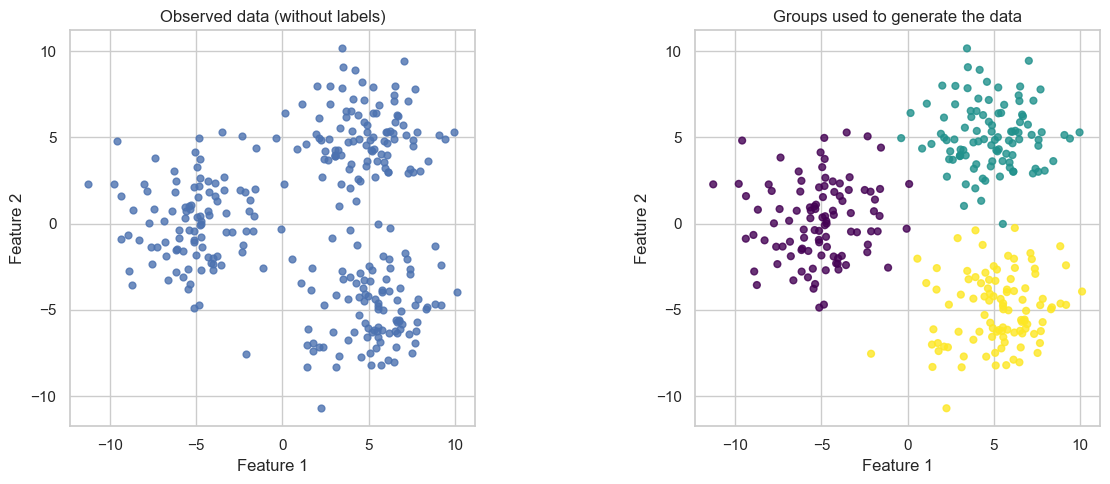

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

sns.set_theme(style="whitegrid", context="notebook")

X, true_group = make_blobs(
    n_samples=300,
    centers=[[-5, 0], [5, 5], [5, -5]],
    cluster_std=2.0,
    random_state=8,
)
print(f"Data shape: {X.shape} (samples, features)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X[:, 0], X[:, 1], s=24, alpha=0.8)
axes[0].set_title("Observed data (without labels)")
axes[1].scatter(X[:, 0], X[:, 1], c=true_group, cmap="viridis", s=24, alpha=0.8)
axes[1].set_title("Groups used to generate the data")
for ax in axes:
    ax.set(xlabel="Feature 1", ylabel="Feature 2")
    ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## 2. Fit a k-means model

We choose $K=3$ for this example. `fit_predict` fits the model using **only** the feature matrix `X` and returns a cluster assignment for every point. `cluster_centers_` contains the fitted centroids, and `inertia_` is the within-cluster sum of squared distances. The cluster numbers are arbitrary: cluster 0 does not necessarily correspond to generated group 0.

K-means can depend on its starting centers. Here, `n_init=10` tries multiple initializations and keeps the result with the smallest inertia.

Centroids:
[[ 5.23 -4.94]
 [-5.17  0.15]
 [ 4.78  5.09]]
Within-cluster sum of squares: 2614.2


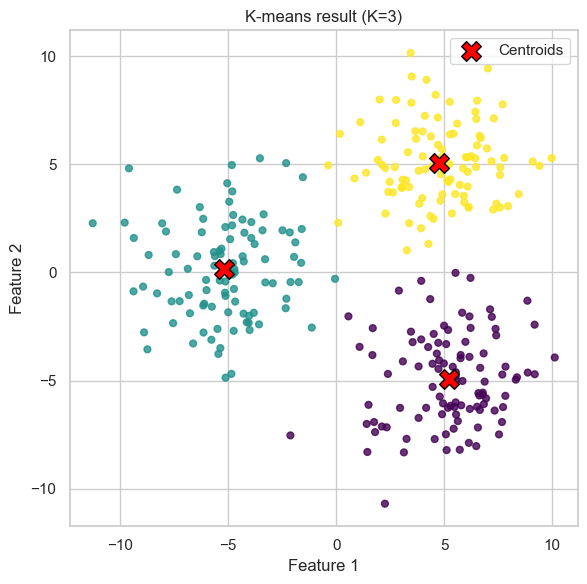

In [2]:
model = KMeans(n_clusters=3, n_init=10, random_state=42)
cluster = model.fit_predict(X)
centers = model.cluster_centers_

print(f"Centroids:\n{centers.round(2)}")
print(f"Within-cluster sum of squares: {model.inertia_:.1f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X[:, 0], X[:, 1], c=cluster, cmap="viridis", s=24, alpha=0.8)
ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=200,
           c="red", edgecolor="black", label="Centroids", zorder=3)
ax.set(title="K-means result (K=3)", xlabel="Feature 1", ylabel="Feature 2")
ax.set_aspect("equal", adjustable="box")
ax.legend()
fig.tight_layout()
plt.show()

## 3. What if we choose a different $K$?

In practice, we usually do not know how many groups are present. To explore the effect of $K$, we will generate a second dataset with four groups, then fit models with $K=3$, $4$, and $5$. The generating labels are not used to fit the models.

With too few clusters, some groups may be combined. With more clusters, a group may be split. Inertia generally decreases as $K$ increases, so a smaller inertia alone does not tell us the best $K$.

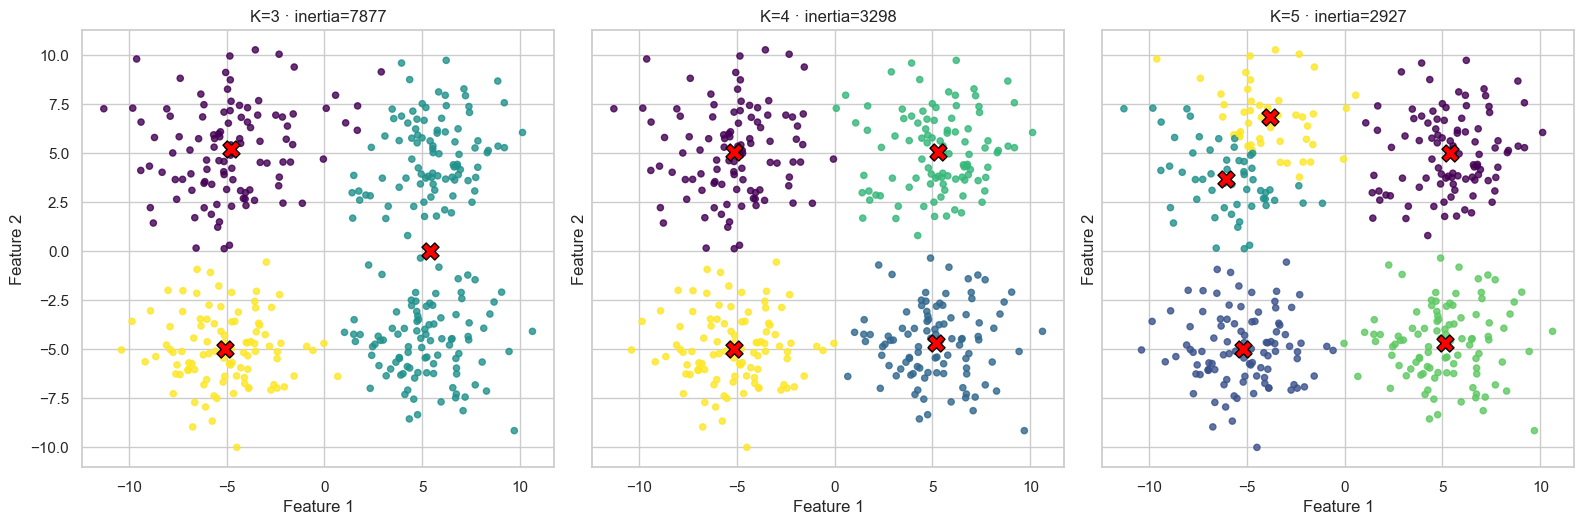

In [3]:
X_four, true_group_four = make_blobs(
    n_samples=400,
    centers=[[-5, 5], [-5, -5], [5, 5], [5, -5]],
    cluster_std=2.0,
    random_state=8,
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, k in zip(axes, [3, 4, 5]):
    model_k = KMeans(n_clusters=k, n_init=10, random_state=42)
    assignments = model_k.fit_predict(X_four)
    centers = model_k.cluster_centers_
    ax.scatter(X_four[:, 0], X_four[:, 1], c=assignments, cmap="viridis",
               s=20, alpha=0.8)
    ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=150,
               c="red", edgecolor="black", zorder=3)
    ax.set(title=f"K={k} · inertia={model_k.inertia_:.0f}",
           xlabel="Feature 1", ylabel="Feature 2")
    ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## Takeaways

- K-means groups observations around $K$ centroids without using labels.
- The choice of $K$, the initial centroids, and the scale of the features can affect the result.
- The synthetic data's generating groups help us interpret the example, but are not required for clustering.

Explore how Lloyd's algorithm alternates between assignments and centroid updates in the [k-means exploration page](kmeans-explorer.qmd).

[← Return to Unsupervised learning](index.qmd)